# Modelos de regresión - Viajes en taxi de Nueva York (enero 2015)

Se entrenaron y compararon modelos de regresión sobre el dataset limpio `yellow_tripdata_2015-01_clean.csv` para predecir la duración del viaje (`trip_duration_min`) a partir de la hora de partida y las coordenadas de partida y llegada.

### Importar datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyproj import Transformer
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, ParameterGrid, train_test_split
from sklearn.preprocessing import StandardScaler

PATH = "../data/yellow_tripdata_2015-01_clean.csv"
CHUNK = 2_000_000
cols = {1: "tpep_pickup_datetime", 5: "pickup_longitude", 6: "pickup_latitude",
        9: "dropoff_longitude", 10: "dropoff_latitude", 19: "trip_duration_min"}

partes = []
for chunk in pd.read_csv(PATH, header=None, skiprows=1, usecols=list(cols), chunksize=CHUNK):
    chunk.columns = list(cols.values())
    pickup = pd.to_datetime(chunk.pop("tpep_pickup_datetime"), format="%Y-%m-%d %H:%M:%S")
    chunk.insert(0, "pickup_hour", pickup.dt.hour + pickup.dt.minute / 60)
    partes.append(chunk.astype(np.float32))
df = pd.concat(partes, ignore_index=True)
del partes

features = ["pickup_hour", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
X = df[features].to_numpy()
y = df["trip_duration_min"].to_numpy(np.float64)
del df

print(f"Filas: {len(X):,}")
print(f"Variables: {features}")

Filas: 12,402,772
Variables: ['pickup_hour', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']


### Pipeline

Se comparan tres modelos sobre las mismas variables de dominio:
- **Lineal**: regresión lineal sin regularización.
- **GB**: gradient boosting (`HistGradientBoostingRegressor`, 500 iteraciones), ajustando la tasa de aprendizaje `learning_rate`.
- **RF**: random forest (`RandomForestRegressor`, 100 árboles, raíz cuadrada de las variables por división), ajustando la profundidad `max_depth`.

Las coordenadas se proyectan en km (Transversa de Mercator centrada en Midtown) y se rotan 29° según la grilla de calles de Manhattan. Las variables de dominio son:
- Armónicos `sin(2πkh/24)` y `cos(2πkh/24)` de la hora de partida, con k = 1, 2, 3.
- Coordenadas proyectadas de partida y llegada, y su distancia a Midtown.
- Distancia en línea recta y Manhattan (L1) entre partida y llegada, e indicador de viajes con menos de 0.1 mi en línea recta.
- Orientación del viaje respecto de la grilla, `cos 2θ` (1 a lo largo de las avenidas, -1 en sentido transversal).
- Interacciones de la distancia en línea recta con los armónicos de la hora y con la distancia de partida y llegada a Midtown.

Por memoria, todos los modelos procesan los datos por bloques: en el modelo lineal las variables se estandarizan y los mínimos cuadrados se resuelven acumulando las ecuaciones normales; en GB y RF las variables se construyen en un único arreglo compacto (`float32` en RF y `float64` en GB, que es el tipo que exige) y la predicción también se hace por bloques. Para cada modelo se selecciona la configuración con menor RMSE medio de validación.

In [2]:
PROYECCION = Transformer.from_crs("EPSG:4326", "+proj=tmerc +lat_0=40.754 +lon_0=-73.984 +ellps=WGS84 +units=km", always_xy=True)
ANGULO = np.deg2rad(29)

def proyectar(lon, lat):
    x, y = PROYECCION.transform(lon, lat)
    return x * np.sin(ANGULO) + y * np.cos(ANGULO), x * np.cos(ANGULO) - y * np.sin(ANGULO)

class Dominio(TransformerMixin, BaseEstimator):
    def __init__(self, armonicos=3):
        self.armonicos = armonicos

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.astype(np.float64)
        p = np.column_stack(proyectar(X[:, 1], X[:, 2]))
        q = np.column_stack(proyectar(X[:, 3], X[:, 4]))
        dx, dy = q[:, 0] - p[:, 0], q[:, 1] - p[:, 1]
        d = np.hypot(dx, dy) / 1.609
        rp, rq = np.hypot(*p.T), np.hypot(*q.T)
        ang = 2 * np.pi * X[:, :1] * np.arange(1, self.armonicos + 1) / 24
        hora = np.hstack([np.sin(ang), np.cos(ang)])
        return np.hstack([
            np.column_stack([d, (np.abs(dx) + np.abs(dy)) / 1.609, d < 0.1, np.cos(2 * np.arctan2(dy, dx)),
                             p, q, rp, rq, d * rp, d * rq]),
            hora, d[:, None] * hora,
        ])

class PorBloques(RegressorMixin, BaseEstimator):
    def _bloques(self, X):
        return (slice(i, i + self.bloque) for i in range(0, len(X), self.bloque))

class MinimosCuadrados(PorBloques):
    def __init__(self, transformacion, bloque=100_000):
        self.transformacion = transformacion
        self.bloque = bloque

    def _disenar(self, X):
        return self.escala_.transform(self.transformacion_.transform(X))

    def fit(self, X, y):
        self.transformacion_ = clone(self.transformacion).fit(X[:self.bloque], y[:self.bloque])
        self.escala_ = StandardScaler()
        for b in self._bloques(X):
            self.escala_.partial_fit(self.transformacion_.transform(X[b]))
        self.intercept_ = y.mean()
        ZtZ, Zty = 0, 0
        for b in self._bloques(X):
            Z = self._disenar(X[b])
            ZtZ, Zty = ZtZ + Z.T @ Z, Zty + Z.T @ (y[b] - self.intercept_)
        self.coef_ = np.linalg.lstsq(ZtZ, Zty, rcond=None)[0]
        return self

    def predict(self, X):
        return np.concatenate([self._disenar(X[b]) @ self.coef_ + self.intercept_ for b in self._bloques(X)])

class Arboles(PorBloques):
    def __init__(self, transformacion, modelo, dtype=np.float32, bloque=100_000):
        self.transformacion = transformacion
        self.modelo = modelo
        self.dtype = dtype
        self.bloque = bloque

    def fit(self, X, y):
        self.transformacion_ = clone(self.transformacion).fit(X[:self.bloque], y[:self.bloque])
        Z = np.empty((len(X), self.transformacion_.transform(X[:1]).shape[1]), dtype=self.dtype)
        for b in self._bloques(X):
            Z[b] = self.transformacion_.transform(X[b])
        self.modelo_ = clone(self.modelo).fit(Z, y)
        return self

    def predict(self, X):
        return np.concatenate([self.modelo_.predict(self.transformacion_.transform(X[b]).astype(self.dtype)) for b in self._bloques(X)])

In [3]:
K = 5
N_CV = 2_000_000
METRICAS = ["MSE", "RMSE", "MAE", "R2"]

# def particionar(X, y):
#     X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67)
#     cv_idx = np.random.default_rng(67).choice(len(X_train), size=min(N_CV, len(X_train)), replace=False)
#     folds = [(cv_idx[tr], cv_idx[va]) for tr, va in KFold(n_splits=K, shuffle=True, random_state=67).split(cv_idx)]
#     print(f"Train + validación: {len(X_train):,}")
#     print(f"Test: {len(X_test):,}")
#     print(f"Muestra para validación cruzada: {len(cv_idx):,}")
#     print(f"Tamaño por fold: {len(folds[0][1]):,}")
#     return X_train, X_test, y_train, y_test, folds

N_MUESTRA = 100_000

def particionar(X, y):
    idx = np.random.default_rng(67).choice(len(X), size=N_MUESTRA, replace=False)
    X_train, X_test, y_train, y_test = train_test_split(X[idx], y[idx], test_size=0.2, random_state=67)
    folds = list(KFold(n_splits=K, shuffle=True, random_state=67).split(X_train))
    print(f"Muestra: {N_MUESTRA:,}")
    print(f"Train + validación: {len(X_train):,}")
    print(f"Test: {len(X_test):,}")
    print(f"Tamaño por fold: {len(folds[0][1]):,}")
    return X_train, X_test, y_train, y_test, folds

def metricas(y, y_pred):
    mse = mean_squared_error(y, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, y_pred), "R2": r2_score(y, y_pred)}

def config(params):
    return ", ".join(f"{k.split('__')[-1]}={v:g}" for k, v in sorted(params.items())) or "-"

def construir(modelo, params):
    return clone(modelo).set_params(**params)

def resumen(res):
    return res.groupby(["modelo", "config"], sort=False)[METRICAS].mean()

def entrenar(modelos, X, y, folds):
    entrenados, params_de, res = {}, {}, []
    for nombre, (modelo, grid) in modelos.items():
        for params in ParameterGrid(grid):
            cfg = config(params)
            params_de[nombre, cfg] = params
            for k, (tr, _) in enumerate(folds):
                m = construir(modelo, params).fit(X[tr], y[tr])
                entrenados[nombre, cfg, k] = m
                res.append({"modelo": nombre, "config": cfg, "fold": k + 1, **metricas(y[tr], m.predict(X[tr]))})
    return entrenados, params_de, pd.DataFrame(res)

def validar(entrenados, X, y, folds):
    res = []
    for (nombre, cfg, k), m in entrenados.items():
        va = folds[k][1]
        res.append({"modelo": nombre, "config": cfg, "fold": k + 1, **metricas(y[va], m.predict(X[va]))})
    return pd.DataFrame(res)

def seleccionar(train_cv, val_cv):
    mejor = dict(val_cv.groupby(["modelo", "config"], sort=False)["RMSE"].mean().groupby(level="modelo", sort=False).idxmin().tolist())
    mejor_df = pd.DataFrame(mejor.items(), columns=["modelo", "config"])
    comparacion = pd.concat({
        "train": train_cv.merge(mejor_df).groupby("modelo", sort=False)[METRICAS].mean(),
        "val": val_cv.merge(mejor_df).groupby("modelo", sort=False)[METRICAS].mean(),
    }, axis=1)
    comparacion.insert(0, "config", mejor_df.set_index("modelo")["config"])
    return mejor, comparacion

def entrenar_final(modelos, mejor, params_de, X, y):
    return {n: construir(modelos[n][0], params_de[n, mejor[n]]).fit(X, y) for n in modelos}

def evaluar(finales, X, y):
    y_pred = {n: m.predict(X) for n, m in finales.items()}
    return y_pred, pd.DataFrame({n: metricas(y, p) for n, p in y_pred.items()}).T

In [4]:
def rejilla(n, ancho, alto, cols=2):
    filas = -(-n // cols)
    fig, axes = plt.subplots(filas, min(n, cols), figsize=(ancho * min(n, cols), alto * filas), squeeze=False, layout="constrained")
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:n]

def graficar_hiperparametros(modelos, val_cv):
    ajustables = [n for n, (_, grid) in modelos.items() if grid]
    fig, axes = rejilla(len(ajustables), 4.5, 3.4, cols=3)
    for ax, nombre in zip(axes, ajustables):
        grid = modelos[nombre][1]
        param, *otros = grid
        for fijos in ParameterGrid({k: grid[k] for k in otros}):
            cfgs = [config({param: v, **fijos}) for v in grid[param]]
            rmse = val_cv[val_cv["modelo"] == nombre].groupby("config")["RMSE"].mean().reindex(cfgs)
            ax.plot(grid[param], rmse, marker="o", label=config(fijos) if fijos else None)
        if max(grid[param]) / min(grid[param]) >= 10:
            ax.set_xscale("log")
        else:
            ax.set_xticks(grid[param])
        ax.set_xlabel(param.split("__")[-1])
        ax.set_ylabel("RMSE (min)")
        ax.set_title(nombre)
        if otros:
            ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    plt.suptitle("RMSE medio de validación según hiperparámetro")
    plt.show()

def graficar_folds(val_cv, mejor):
    sel = val_cv.merge(pd.DataFrame(mejor.items(), columns=["modelo", "config"]))
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
    w = 0.8 / len(mejor)
    folds_x = np.arange(1, K + 1)
    for ax, m in zip(axes, ["RMSE", "MAE", "R2"]):
        for i, nombre in enumerate(mejor):
            ax.bar(folds_x - 0.4 + w * (i + 0.5), sel.loc[sel["modelo"] == nombre, m], w, label=nombre)
        ax.set_xticks(folds_x)
        ax.set_xlabel("Fold")
        ax.set_title(m)
        ax.grid(alpha=0.3)
    handles, leg_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, leg_labels, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
    plt.suptitle("Métricas de validación por fold")
    plt.tight_layout()
    plt.show()

def graficar_test(y, y_pred, n=500_000):
    sample = np.random.default_rng(67).choice(len(y), size=min(n, len(y)), replace=False)
    y_s = y[sample]
    y_max = np.quantile(y_s, 0.99)
    res_s = {nombre: y_s - p[sample] for nombre, p in y_pred.items()}
    res_lim = max(np.quantile(np.abs(r), 0.99) for r in res_s.values())

    fig, axes = rejilla(len(y_pred), 4, 4, cols=3)
    for ax, nombre in zip(axes, y_pred):
        ax.scatter(y_s, y_pred[nombre][sample], s=8, alpha=0.35, rasterized=True)
        ax.plot([0, y_max], [0, y_max], color="tab:red", lw=2, ls="--")
        ax.set_xlim(0, y_max)
        ax.set_ylim(0, y_max)
        ax.set_xlabel("Duración real (min)")
        ax.set_ylabel("Duración predicha (min)")
        ax.set_title(nombre)
        ax.grid(alpha=0.3)
    plt.suptitle("Valores reales vs predichos")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 3.6))
    bins = np.linspace(-res_lim, res_lim, 61)
    for nombre, r in res_s.items():
        ax.hist(r.clip(-res_lim, res_lim), bins=bins, histtype="step", lw=1.2, label=nombre)
    ax.set_xlabel("Residuo (min)")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
    ax.grid(alpha=0.3)
    plt.title("Distribución de los residuos")
    plt.tight_layout()
    plt.show()

### Partición de datos

Se reserva el 20% de los datos como conjunto de test. Del 80% restante se toma una muestra aleatoria de 2 M de viajes que se divide en K = 5 folds para validación cruzada (entrenamiento y validación).

In [5]:
GB = HistGradientBoostingRegressor(max_iter=500, early_stopping=False, random_state=67)
RF = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=67)
grid_gb = {"modelo__learning_rate": [0.05, 0.1]}
grid_rf = {"modelo__max_depth": [12, 20, 30]}

modelos = {
    "Lineal": (MinimosCuadrados(Dominio()), {}),
    "GB": (Arboles(Dominio(), GB, dtype=np.float64), grid_gb),
    "RF": (Arboles(Dominio(), RF), grid_rf),
}

X_train, X_test, y_train, y_test, folds = particionar(X, y)
del X, y

Muestra: 100,000
Train + validación: 80,000
Test: 20,000
Tamaño por fold: 16,000


### Entrenamiento

Para cada modelo y configuración de hiperparámetros se entrena un modelo por fold con los K - 1 folds restantes.

In [6]:
entrenados, params_de, train_cv = entrenar(modelos, X_train, y_train, folds)
resumen(train_cv).round(4)

MSE    RMSE     MAE      R2
modelo config                                             
Lineal -                   30.6040  5.5316  3.3905  0.6481
GB     learning_rate=0.05  18.4822  4.2983  2.6413  0.7875
       learning_rate=0.1   15.1580  3.8925  2.4414  0.8257
RF     max_depth=12        20.8088  4.5610  2.7736  0.7607
       max_depth=20        15.6118  3.9503  2.2059  0.8205
       max_depth=30        15.0310  3.8761  2.1051  0.8272

### Validación

Cada modelo se evalúa sobre el fold que no se usó en su entrenamiento.

In [7]:
val_cv = validar(entrenados, X_train, y_train, folds)
resumen(val_cv).round(4)

MSE    RMSE     MAE      R2
modelo config                                             
Lineal -                   30.6641  5.5290  3.3927  0.6483
GB     learning_rate=0.05  25.8592  5.0724  2.9456  0.7038
       learning_rate=0.1   26.1406  5.1003  2.9501  0.7006
RF     max_depth=12        27.2154  5.2057  3.0943  0.6881
       max_depth=20        26.6683  5.1525  3.0288  0.6945
       max_depth=30        26.6059  5.1465  3.0258  0.6952

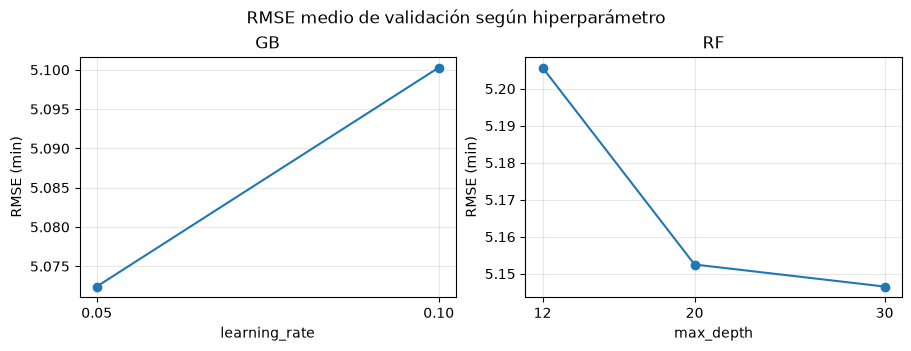

In [8]:
graficar_hiperparametros(modelos, val_cv)

In [9]:
mejor, comparacion = seleccionar(train_cv, val_cv)
comparacion.round(4)

config    train                              val          \
                                MSE    RMSE     MAE      R2      MSE    RMSE   
modelo                                                                         
Lineal                   -  30.6040  5.5316  3.3905  0.6481  30.6641  5.5290   
GB      learning_rate=0.05  18.4822  4.2983  2.6413  0.7875  25.8592  5.0724   
RF            max_depth=30  15.0310  3.8761  2.1051  0.8272  26.6059  5.1465   

                        
           MAE      R2  
modelo                  
Lineal  3.3927  0.6483  
GB      2.9456  0.7038  
RF      3.0258  0.6952

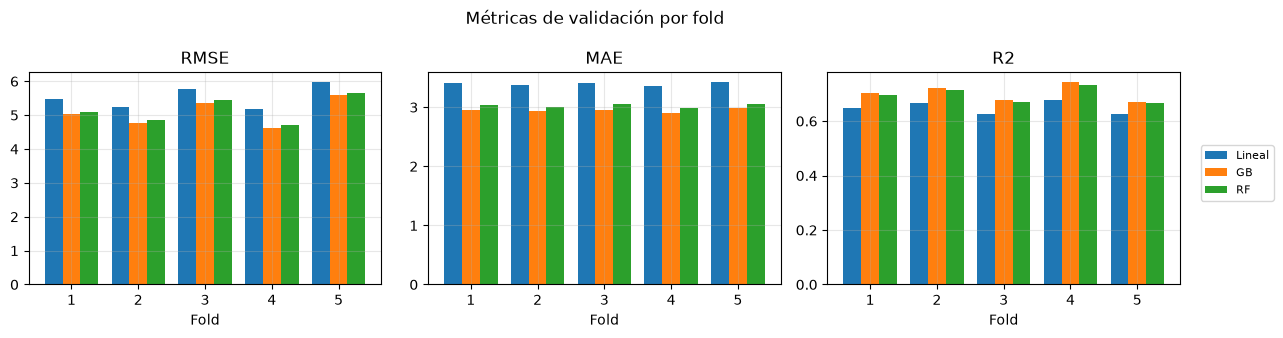

In [10]:
graficar_folds(val_cv, mejor)

### Modelo final

Cada modelo se reentrena con su mejor configuración sobre todo el conjunto de entrenamiento y validación.

In [11]:
finales = entrenar_final(modelos, mejor, params_de, X_train, y_train)
print("Número de variables por modelo lineal:")
for nombre, m in finales.items():
    if isinstance(m, MinimosCuadrados):
        print(f"  {nombre}: {len(m.coef_)}")

Número de variables por modelo lineal:
  Lineal: 24


### Evaluación en test

Los modelos finales se evalúan sobre el conjunto de test. Las gráficas se realizaron sobre una muestra aleatoria de 500 mil viajes del conjunto de test, recortando los ejes al percentil 99 únicamente para mejorar la visualización.

In [12]:
y_pred, test = evaluar(finales, X_test, y_test)
test.round(4)

,MSE,RMSE,MAE,R2
Lineal,29.1853,5.4023,3.4075,0.6547
GB,23.9918,4.8981,2.9376,0.7161
RF,24.7229,4.9722,3.0088,0.7075


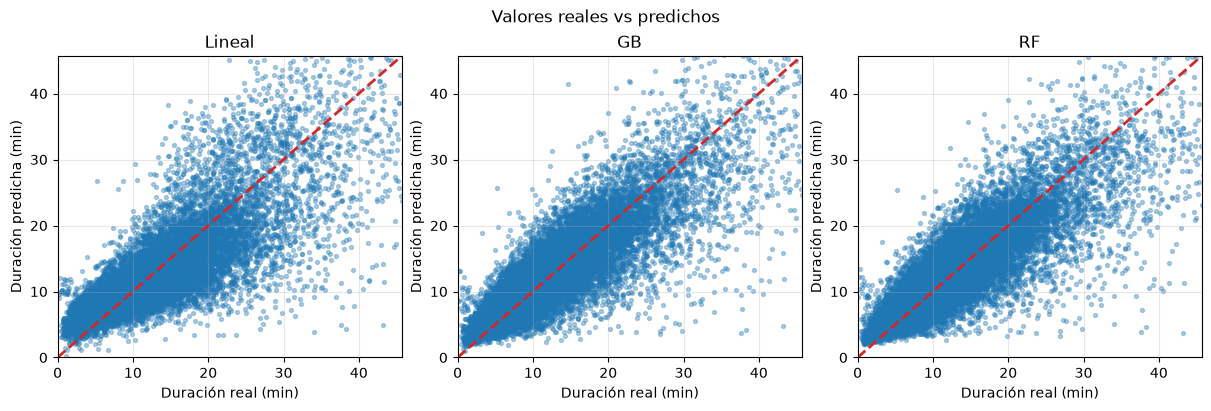

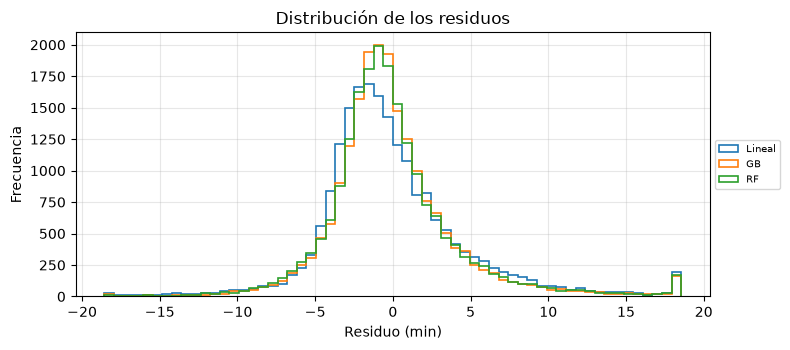

In [13]:
graficar_test(y_test, y_pred)